# EN4554 - Deep Learning for Vision
## Assignment 2: Convolutional Neural Networks

**Name:** Savindu Dilshan Wickramasinghe

**Index number:** 220701X

**GitHub repository:** https://github.com/Savidilsh/EN4554-Assignment2-CNNs

**AI assistance acknowledgment:** Claude (Anthropic) was used to help write and debug the code in this notebook. I have reviewed and understood all of the code and the results.

## Setup

The notebook runs on a Colab T4 or a local GPU. The outputs below were produced on an NVIDIA GTX 1650. The normalized dataset is kept on the GPU, and batching and augmentation are done with tensor operations, which is faster than a CPU `DataLoader`. Mixed precision is used only on GPUs with tensor cores. Completed training runs are saved in `results/` and are loaded instead of retrained when the notebook is run again.

In [1]:
import copy, json, math, os, random, time, warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from IPython.display import display

warnings.filterwarnings("ignore", message=".*lr_scheduler.step.*")
pd.set_option("display.precision", 4)

SEED = 0

try:  # on Colab, keep data and results on Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/EN4554_A2"
except ImportError:
    BASE = "."
DATA_DIR = os.path.join(BASE, "data")
RESULTS = os.path.join(BASE, "results")
FIGS = os.path.join(BASE, "figures")
CKPT = os.path.join(BASE, "checkpoints")
for d in (DATA_DIR, RESULTS, FIGS, CKPT):
    os.makedirs(d, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# fp16 autocast only on GPUs with tensor cores
AMP = (device.type == "cuda" and torch.cuda.get_device_capability()[0] >= 7
       and "GTX" not in torch.cuda.get_device_name(0))
torch.backends.cudnn.benchmark = True


def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def savefig(name):
    plt.savefig(f"{FIGS}/{name}.png", dpi=130, bbox_inches="tight")


_LOG = None


def log(msg):
    """Print a training log line and keep it with the saved run."""
    print(msg, flush=True)
    if _LOG is not None:
        _LOG.append(msg)


def cached(name, fn):
    """Run fn() once and save the result with its training log in RESULTS/name.json.
    If the run already exists, load it and print its saved training log."""
    global _LOG
    path = f"{RESULTS}/{name}.json"
    if os.path.exists(path):
        with open(path) as f:
            out = json.load(f)
        print(f"Loaded saved run: {name}")
        for line in out.get("_log", []):
            print(line)
        return out
    _LOG = []
    try:
        out = fn()
        out["_log"] = _LOG
    finally:
        _LOG = None
    with open(path, "w") as f:
        json.dump(out, f)
    return out


set_seed()
print("Device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "", "| mixed precision:", AMP)
print("PyTorch", torch.__version__)

Device: cuda NVIDIA GeForce GTX 1650 | mixed precision: False
PyTorch 2.11.0+cu128


### Data

CIFAR-10 is split into 45,000 training and 5,000 validation images using seed 0. Normalization uses the per-channel mean and standard deviation of the 45,000 training images only. The test set stays on the CPU and is used only for the final evaluation in Task 4.

train (45000, 3, 32, 32) val (5000, 3, 32, 32) test (10000, 3, 32, 32)
per-channel mean (R, G, B): [0.4912 0.482  0.4464]  std: [0.2472 0.2436 0.2617]


,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
train (45k),4518,4492,4506,4496,4468,4493,4498,4494,4502,4533
validation (5k),482,508,494,504,532,507,502,506,498,467


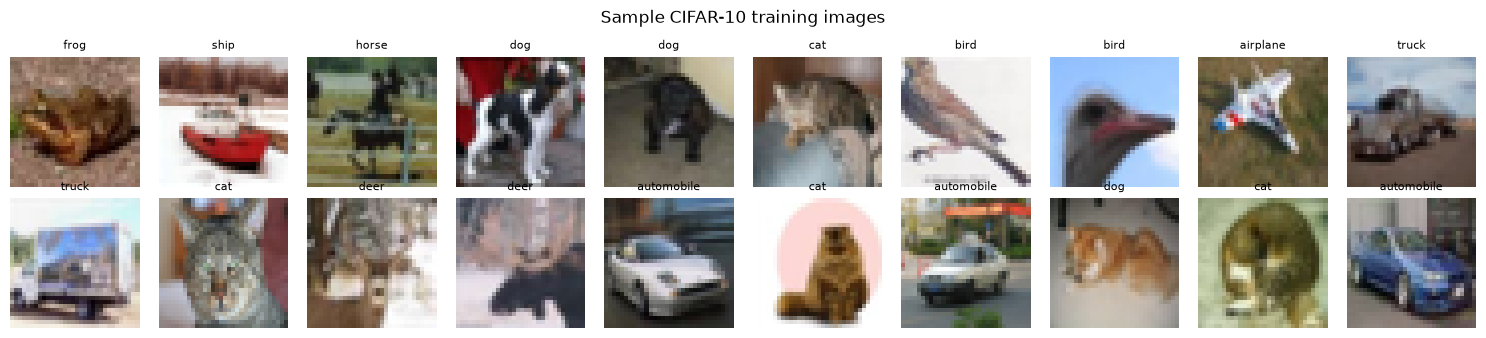

In [2]:
train_set = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
test_set = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)
CLASSES = train_set.classes

X_all = torch.from_numpy(train_set.data).permute(0, 3, 1, 2).contiguous()  # uint8, N x 3 x 32 x 32
y_all = torch.tensor(train_set.targets)
perm = torch.randperm(len(y_all), generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[:45000], perm[45000:]

# per-channel statistics of the 45k training images only
MEAN = torch.stack([X_all[tr_idx, c].float().div(255).mean() for c in range(3)])
STD = torch.stack([X_all[tr_idx, c].float().div(255).std() for c in range(3)])


def normalize(X):
    return (X.float().div(255) - MEAN[:, None, None]) / STD[:, None, None]


X_tr, y_tr = normalize(X_all[tr_idx]).to(device), y_all[tr_idx].to(device)
X_va, y_va = normalize(X_all[va_idx]).to(device), y_all[va_idx].to(device)
# the test set stays on the CPU and is only used once, in Task 4
X_te = normalize(torch.from_numpy(test_set.data).permute(0, 3, 1, 2))
y_te = torch.tensor(test_set.targets)

print("train", tuple(X_tr.shape), "val", tuple(X_va.shape), "test", tuple(X_te.shape))
print("per-channel mean (R, G, B):", MEAN.numpy().round(4), " std:", STD.numpy().round(4))
display(pd.DataFrame({"train (45k)": torch.bincount(y_tr.cpu()).tolist(),
                      "validation (5k)": torch.bincount(y_va.cpu()).tolist()}, index=CLASSES).T)

# a few (un-normalized) training images
fig, axes = plt.subplots(2, 10, figsize=(15, 3.4))
for k, ax in enumerate(axes.flat):
    i = int(tr_idx[k])
    ax.imshow(train_set.data[i]); ax.set_title(CLASSES[train_set.targets[i]], fontsize=8); ax.axis("off")
plt.suptitle("Sample CIFAR-10 training images"); plt.tight_layout(); plt.show()

### Training utilities

`flip_crop`, `cutout` and `mixup` work on GPU batches. `fit` trains a model and records the training loss, validation loss and validation accuracy after every epoch (and, optionally, the accuracy on the clean training images).

In [3]:
def batches(X, y, bs, shuffle=True):
    n = len(y)
    idx = torch.randperm(n, device=X.device) if shuffle else torch.arange(n, device=X.device)
    for i in range(0, n, bs):
        j = idx[i:i + bs]
        yield X[j], y[j]


def flip_crop(x, pad=4):
    """Random horizontal flip + random 32x32 crop from a zero-padded (= mean-padded) image."""
    N, C, H, W = x.shape
    flip = torch.rand(N, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))
    i = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    j = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    rows = (i[:, None] + torch.arange(H, device=x.device))[:, None, :, None]
    cols = (j[:, None] + torch.arange(W, device=x.device))[:, None, None, :]
    n_idx = torch.arange(N, device=x.device)[:, None, None, None]
    c_idx = torch.arange(C, device=x.device)[None, :, None, None]
    return xp[n_idx, c_idx, rows, cols]


def cutout(x, size=16):
    """Zero (= mean) a size x size square at a random centre of each image (may be clipped at the border)."""
    N, _, H, W = x.shape
    cy = torch.randint(0, H, (N, 1, 1), device=x.device)
    cx = torch.randint(0, W, (N, 1, 1), device=x.device)
    yy = torch.arange(H, device=x.device)[None, :, None]
    xx = torch.arange(W, device=x.device)[None, None, :]
    mask = (yy >= cy - size // 2) & (yy < cy + size // 2) & (xx >= cx - size // 2) & (xx < cx + size // 2)
    return x * (~mask)[:, None].to(x.dtype)


def mixup(x, y, alpha):
    """Return mixed inputs, both label sets and the mixing coefficient lambda ~ Beta(alpha, alpha)."""
    lam = float(np.random.beta(alpha, alpha))
    p = torch.randperm(len(y), device=x.device)
    return lam * x + (1 - lam) * x[p], y, y[p], lam


def compose(*fs):
    def f(x):
        for g in fs:
            x = g(x)
        return x
    return f


def cosine_warmup(opt, total_steps, warmup_steps=0):
    """Per-iteration LR multiplier: linear warm-up, then cosine decay to 0."""
    def mult(s):
        if s < warmup_steps:
            return (s + 1) / warmup_steps
        p = (s - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * min(p, 1.0)))
    return torch.optim.lr_scheduler.LambdaLR(opt, mult)


@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval()
    n = len(y)
    loss, correct = 0.0, 0
    for i in range(0, n, bs):
        xb, yb = X[i:i + bs].to(device), y[i:i + bs].to(device)
        with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
            out = model(xb)
        loss += F.cross_entropy(out.float(), yb, reduction="sum").item()
        correct += (out.argmax(1) == yb).sum().item()
    return loss / n, correct / n


def fit(model, opt, n_epochs, X, y, bs=128, aug=None, mixup_alpha=0.0, sched=None,
        label_smoothing=0.0, amp=AMP, eval_train=False, tag=""):
    """Train for n_epochs; returns per-epoch train loss / val loss / val acc (and clean train acc)."""
    scaler = torch.amp.GradScaler(device.type, enabled=amp)
    H = dict(train_loss=[], val_loss=[], val_acc=[], train_acc=[], iter_loss=[], time=[])
    for ep in range(n_epochs):
        model.train()
        t0, losses = time.time(), []
        for xb, yb in batches(X, y, bs):
            if aug is not None:
                xb = aug(xb)
            with torch.autocast(device.type, dtype=torch.float16, enabled=amp):
                if mixup_alpha > 0:
                    xb, ya, yb2, lam = mixup(xb, yb, mixup_alpha)
                    out = model(xb)
                    loss = lam * F.cross_entropy(out, ya) + (1 - lam) * F.cross_entropy(out, yb2)
                else:
                    out = model(xb)
                    loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            if sched is not None:
                sched.step()
            losses.append(loss.detach().float())
        il = torch.stack(losses).cpu().tolist()
        H["iter_loss"] += il
        H["train_loss"].append(float(np.mean(il)))
        vl, va = evaluate(model, X_va, y_va)
        H["val_loss"].append(vl); H["val_acc"].append(va)
        if eval_train:
            H["train_acc"].append(evaluate(model, X, y)[1])
        H["time"].append(time.time() - t0)
        msg = f"[{tag}] ep {ep + 1:3d}/{n_epochs} loss {H['train_loss'][-1]:.4f} val_acc {va:.4f}"
        if eval_train:
            msg += f" train_acc {H['train_acc'][-1]:.4f}"
        if ep == 0 or (ep + 1) % max(1, n_epochs // 10) == 0 or ep == n_epochs - 1:
            log(msg + f" ({H['time'][-1]:.1f}s)")
        if not math.isfinite(H["train_loss"][-1]):
            log(f"[{tag}] diverged (non-finite loss), stopping early")
            break
    return H


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def smooth(v, k=50):
    v = np.asarray(v, dtype=float)
    if len(v) < k:
        return v
    return np.convolve(v, np.ones(k) / k, mode="valid")

## Task 1: Backpropagation

### 1(a): Manual layers and MLP

Each layer stores what it needs in `forward` and applies the chain rule in `backward`. No autograd is used.

* **Linear** $Y = XW + b$: $\;\partial L/\partial W = X^\top G$, $\;\partial L/\partial b = \sum_n G_n$, $\;\partial L/\partial X = G W^\top$, where $G = \partial L/\partial Y$.
* **ReLU** $y=\max(0,x)$: $\;\partial L/\partial x = G \odot \mathbb 1[x>0]$.
* **Sigmoid** (used in 1(d)) $s=\sigma(x)$: $\;\partial L/\partial x = G \odot s(1-s)$.
* **Softmax cross-entropy**, averaged over the batch: $L = -\frac1N\sum_n \log p_{n,y_n}$, $\;\partial L/\partial z = (p - \text{onehot}(y))/N$. The row maximum is subtracted before the exponential for numerical stability.

In [4]:
class Linear:
    def __init__(self, d_in, d_out, init="he", dtype=torch.float32, dev=device, gen=None):
        std = math.sqrt(2.0 / d_in) if init == "he" else math.sqrt(2.0 / (d_in + d_out))  # He or Xavier
        self.W = torch.randn(d_in, d_out, generator=gen, dtype=dtype).to(dev) * std
        self.b = torch.zeros(d_out, dtype=dtype, device=dev)
        self.dW = self.db = None

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, g):
        self.dW = self.x.T @ g
        self.db = g.sum(0)
        return g @ self.W.T

    def params(self):
        return [(self.W, self.dW), (self.b, self.db)]


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, g):
        return g * self.mask

    def params(self):
        return []


class Sigmoid:
    def forward(self, x):
        self.s = 1.0 / (1.0 + torch.exp(-x))
        return self.s

    def backward(self, g):
        return g * self.s * (1 - self.s)

    def params(self):
        return []


class SoftmaxCrossEntropy:
    def forward(self, z, y):
        z = z - z.max(dim=1, keepdim=True).values
        logp = z - torch.log(torch.exp(z).sum(dim=1, keepdim=True))
        self.p, self.y = torch.exp(logp), y
        return -logp[torch.arange(len(y)), y].mean()

    def backward(self):
        g = self.p.clone()
        g[torch.arange(len(self.y)), self.y] -= 1
        return g / len(self.y)


class MLP:
    def __init__(self, sizes, act="relu", init="he", dtype=torch.float32, dev=device, seed=SEED):
        gen = torch.Generator().manual_seed(seed)
        Act = ReLU if act == "relu" else Sigmoid
        self.layers = []
        for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:])):
            self.layers.append(Linear(a, b, init, dtype, dev, gen))
            if i < len(sizes) - 2:
                self.layers.append(Act())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)

    def backward(self):
        g = self.loss_fn.backward()
        for layer in reversed(self.layers):
            g = layer.backward(g)
        return g  # dL/dx

    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]

    def sgd_step(self, lr):
        for lin in self.linears():
            lin.W -= lr * lin.dW
            lin.b -= lr * lin.db

### 1(b): Gradient check

A small MLP (12-10-8-5) in float64 is evaluated on a random batch of 6 inputs. Every parameter gradient and the input gradient are compared with autograd and with centred finite differences, $\big(L(\theta+h e_i) - L(\theta-h e_i)\big)/2h$ with $h=10^{-6}$. The relative error is $\|g_m - g\|_2 / (\|g_m\|_2 + \|g\|_2)$. The check is done for a ReLU and a sigmoid network.

In [5]:
def rel_err(a, b):
    return ((a - b).norm() / max((a.norm() + b.norm()).item(), 1e-12)).item()


def grad_check(act):
    torch.manual_seed(1)
    net = MLP([12, 10, 8, 5], act=act, dtype=torch.float64, dev="cpu", seed=1)
    for lin in net.linears():  # non-zero biases so that their gradients are tested properly
        lin.b += 0.1 * torch.randn_like(lin.b)
    x = torch.randn(6, 12, dtype=torch.float64)
    y = torch.randint(0, 5, (6,))

    # manual gradients
    net.loss(x, y)
    dx_manual = net.backward()
    manual = {}
    for k, lin in enumerate(net.linears()):
        manual[f"W{k + 1}"], manual[f"b{k + 1}"] = lin.dW.clone(), lin.db.clone()
    manual["x"] = dx_manual

    # autograd on the same weights
    leaves = {}
    h = x.clone().requires_grad_(True)
    leaves["x"] = h
    lins = net.linears()
    for k, lin in enumerate(lins):
        W = lin.W.clone().requires_grad_(True); b = lin.b.clone().requires_grad_(True)
        leaves[f"W{k + 1}"], leaves[f"b{k + 1}"] = W, b
        h = h @ W + b
        if k < len(lins) - 1:
            h = torch.relu(h) if act == "relu" else torch.sigmoid(h)
    F.cross_entropy(h, y).backward()

    # centred finite differences
    def fd(tensor, eps=1e-6):
        g = torch.zeros_like(tensor)
        flat, gflat = tensor.view(-1), g.view(-1)
        for i in range(flat.numel()):
            old = flat[i].item()
            flat[i] = old + eps; lp = net.loss(x, y).item()
            flat[i] = old - eps; lm = net.loss(x, y).item()
            flat[i] = old
            gflat[i] = (lp - lm) / (2 * eps)
        return g

    rows = []
    for name, g_m in manual.items():
        if name == "x":
            target = x
        else:
            k = int(name[1:]) - 1
            target = lins[k].W if name[0] == "W" else lins[k].b
        g_auto = leaves[name].grad
        g_fd = fd(target)
        rows.append((act, name, tuple(g_m.shape), rel_err(g_m, g_auto), rel_err(g_m, g_fd),
                     torch.allclose(g_m, g_auto), torch.allclose(g_m, g_fd, atol=1e-7)))
    return rows


gc = pd.DataFrame([r for act in ("relu", "sigmoid") for r in grad_check(act)],
                  columns=["activation", "gradient", "shape", "rel. error vs autograd", "rel. error vs FD",
                           "allclose (autograd)", "allclose (FD)"])
display(gc.style.format({"rel. error vs autograd": "{:.2e}", "rel. error vs FD": "{:.2e}"}).hide(axis="index"))
print("all gradients match:", bool(gc["allclose (autograd)"].all() and gc["allclose (FD)"].all()))

activation,gradient,shape,rel. error vs autograd,rel. error vs FD,allclose (autograd),allclose (FD)
relu,W1,"(12, 10)",7.31e-17,6.95e-10,True,True
relu,b1,"(10,)",5.76e-17,5.73e-10,True,True
relu,W2,"(10, 8)",7.16e-17,4.20e-10,True,True
relu,b2,"(8,)",1.03e-16,6.51e-10,True,True
relu,W3,"(8, 5)",3.98e-17,3.09e-10,True,True
relu,b3,"(5,)",1.61e-17,3.77e-10,True,True
relu,x,"(6, 12)",5.83e-17,6.39e-10,True,True
sigmoid,W1,"(12, 10)",1.35e-16,7.65e-09,True,True
sigmoid,b1,"(10,)",1.62e-16,1.24e-08,True,True
sigmoid,W2,"(10, 8)",1.09e-16,3.10e-09,True,True


all gradients match: True


**Interpretation:** All manual gradients match autograd with relative errors around **1e-16**, which is floating-point rounding in float64. Against finite differences the errors are **1e-10 to 1e-8**. This is the expected accuracy of the finite-difference approximation with $h=10^{-6}$: the truncation error is of order $h^2$ and the rounding error of order $\epsilon/h$. `torch.allclose` is True for every parameter and for the input gradient, for both activations, so the backward passes are correct.

### 1(c): Training the manual MLP

MLP 3072-512-256-10 with ReLU and He initialization, trained with mini-batch SGD (batch 128, learning rate 0.05 with cosine decay, 30 epochs). Only the manual forward and backward passes from 1(a) are used.

Loaded saved run: task1c_mlp
ep  1 train_loss 1.6921 train_acc 0.4939 val_loss 1.6016 val_acc 0.4410
ep  2 train_loss 1.4097 train_acc 0.5465 val_loss 1.5511 val_acc 0.4730
ep  3 train_loss 1.2818 train_acc 0.5716 val_loss 1.5657 val_acc 0.4734
ep  4 train_loss 1.1786 train_acc 0.6315 val_loss 1.4843 val_acc 0.4878
ep  5 train_loss 1.0869 train_acc 0.6616 val_loss 1.4841 val_acc 0.5012
ep  6 train_loss 1.0011 train_acc 0.6935 val_loss 1.4861 val_acc 0.5048
ep  7 train_loss 0.9169 train_acc 0.7329 val_loss 1.4939 val_acc 0.5058
ep  8 train_loss 0.8416 train_acc 0.7376 val_loss 1.5961 val_acc 0.4890
ep  9 train_loss 0.7701 train_acc 0.7745 val_loss 1.5643 val_acc 0.5058
ep 10 train_loss 0.6905 train_acc 0.7895 val_loss 1.6438 val_acc 0.5006
ep 11 train_loss 0.6193 train_acc 0.8361 val_loss 1.6131 val_acc 0.5136
ep 12 train_loss 0.5499 train_acc 0.8638 val_loss 1.6423 val_acc 0.5052
ep 13 train_loss 0.4822 train_acc 0.8467 val_loss 1.7841 val_acc 0.4948
ep 14 train_loss 0.4214 train_acc 0

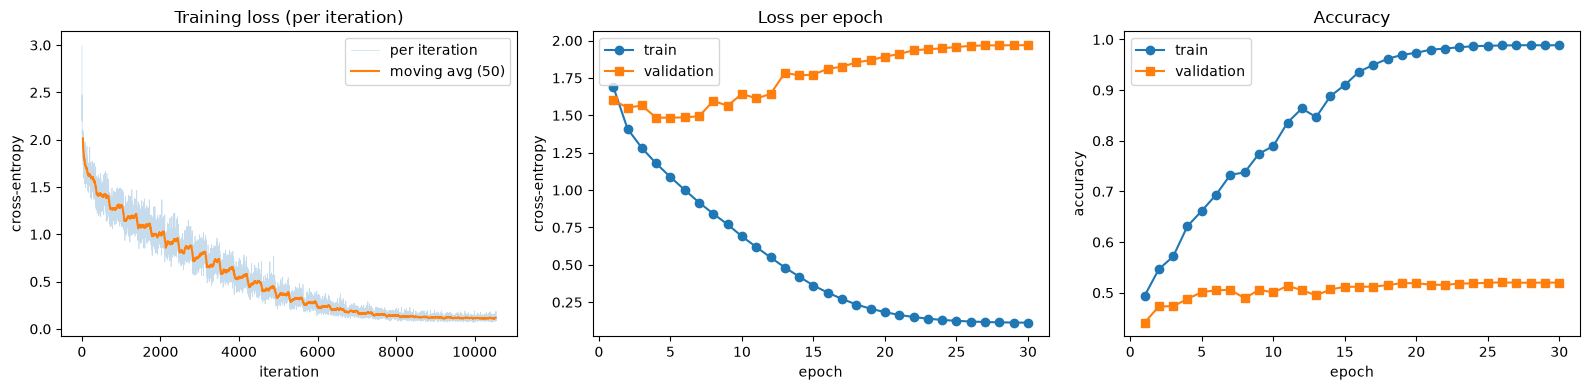

Final validation accuracy: 0.5200 (best 0.5204)


In [6]:
def train_manual_mlp(n_epochs=30, lr0=0.05, bs=128):
    set_seed()
    net = MLP([3072, 512, 256, 10], act="relu", init="he")
    Xf_tr, Xf_va = X_tr.reshape(len(X_tr), -1), X_va.reshape(len(X_va), -1)
    steps = n_epochs * math.ceil(len(y_tr) / bs)
    H = dict(iter_loss=[], train_loss=[], val_loss=[], val_acc=[], train_acc=[])
    step = 0
    for ep in range(n_epochs):
        losses = []
        for xb, yb in batches(Xf_tr, y_tr, bs):
            lr = lr0 * 0.5 * (1 + math.cos(math.pi * step / steps))
            losses.append(net.loss(xb, yb))
            net.backward()
            net.sgd_step(lr)
            step += 1
        il = torch.stack(losses).cpu().tolist()
        H["iter_loss"] += il
        H["train_loss"].append(float(np.mean(il)))

        def acc_loss(Xf, y):
            out = torch.cat([net.forward(Xf[i:i + 1000]) for i in range(0, len(y), 1000)])
            return net.loss_fn.forward(out, y).item(), (out.argmax(1) == y).float().mean().item()

        vl, va = acc_loss(Xf_va, y_va)
        H["val_loss"].append(vl); H["val_acc"].append(va)
        H["train_acc"].append(acc_loss(Xf_tr, y_tr)[1])
        log(f"ep {ep + 1:2d} train_loss {H['train_loss'][-1]:.4f} train_acc {H['train_acc'][-1]:.4f} "
              f"val_loss {vl:.4f} val_acc {va:.4f}")
    return H


H1c = cached("task1c_mlp", lambda: train_manual_mlp(30))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(H1c["iter_loss"], alpha=0.25, lw=0.5, label="per iteration")
ax[0].plot(np.arange(len(smooth(H1c["iter_loss"]))) + 25, smooth(H1c["iter_loss"]), label="moving avg (50)")
ax[0].set(xlabel="iteration", ylabel="cross-entropy", title="Training loss (per iteration)"); ax[0].legend()
ep = np.arange(1, len(H1c["train_loss"]) + 1)
ax[1].plot(ep, H1c["train_loss"], "o-", label="train"); ax[1].plot(ep, H1c["val_loss"], "s-", label="validation")
ax[1].set(xlabel="epoch", ylabel="cross-entropy", title="Loss per epoch"); ax[1].legend()
ax[2].plot(ep, H1c["train_acc"], "o-", label="train"); ax[2].plot(ep, H1c["val_acc"], "s-", label="validation")
ax[2].set(xlabel="epoch", ylabel="accuracy", title="Accuracy"); ax[2].legend()
plt.tight_layout(); savefig("task1c_mlp"); plt.show()
print(f"Final validation accuracy: {H1c['val_acc'][-1]:.4f} (best {max(H1c['val_acc']):.4f})")

**Interpretation:** The training loss falls from about 2.3 to **0.11**, and the final validation accuracy is **52.0%**. Training accuracy reaches 98.9%, so the model overfits strongly. The validation loss is lowest at epoch 5 (1.48) and then rises to 1.97 while the validation accuracy stays around 51-52%, so the model becomes more confident on the validation images it gets wrong.

An MLP on flattened pixels does not use the local structure of images and is not translation invariant. With 1.7M parameters it memorises the training images instead of learning features that generalise. The CNNs in the later tasks reach much higher accuracy with fewer parameters.

### 1(d): Gradient norms in a 10-layer MLP

The network has 10 linear layers (3072 → 9 hidden layers of 256 → 10); layer 1 is next to the input. At initialization, $\|\partial L/\partial W_\ell\|_F$ is computed on a fixed batch of 512 training images for sigmoid and ReLU. The same weights are used for both activations. Two initializations are shown, He ($\mathrm{Var}(W)=2/d_{in}$) and Xavier ($\mathrm{Var}(W)=2/(d_{in}+d_{out})$), each averaged over 5 seeds.

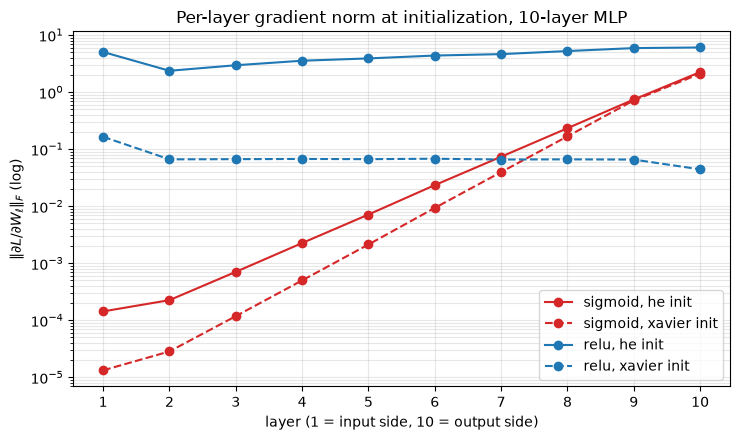

,layer 1,layer 2,layer 3,layer 4,layer 5,layer 6,layer 7,layer 8,layer 9,layer 10,layer 1 / layer 10
"sigmoid, he init",1.4e-04,2.3e-04,7.1e-04,2.3e-03,7.1e-03,2.3e-02,7.4e-02,2.3e-01,7.4e-01,2.2e+00,6.4e-05
"sigmoid, xavier init",1.3e-05,2.8e-05,1.2e-04,5.0e-04,2.1e-03,9.3e-03,4.0e-02,1.7e-01,7.2e-01,2.1e+00,6.3e-06
"relu, he init",5.0e+00,2.4e+00,3.0e+00,3.5e+00,3.9e+00,4.4e+00,4.6e+00,5.2e+00,5.9e+00,6.1e+00,8.3e-01
"relu, xavier init",1.6e-01,6.6e-02,6.7e-02,6.7e-02,6.7e-02,6.8e-02,6.6e-02,6.6e-02,6.6e-02,4.4e-02,3.7e+00


In [7]:
def layer_grad_norms(act, init, seeds=range(5)):
    xb, yb = X_tr[:512].reshape(512, -1), y_tr[:512]
    norms = []
    for s in seeds:
        net = MLP([3072] + [256] * 9 + [10], act=act, init=init, seed=s)
        net.loss(xb, yb)
        net.backward()
        norms.append([lin.dW.norm().item() for lin in net.linears()])
    return np.mean(norms, axis=0)


fig, ax = plt.subplots(figsize=(7.5, 4.5))
gn = {}
for act, c in (("sigmoid", "tab:red"), ("relu", "tab:blue")):
    for init, ls in (("he", "-"), ("xavier", "--")):
        g = gn[f"{act}, {init} init"] = layer_grad_norms(act, init)
        ax.semilogy(range(1, 11), g, ls, color=c, marker="o", label=f"{act}, {init} init")
ax.set(xlabel="layer (1 = input side, 10 = output side)", ylabel=r"$\|\partial L/\partial W_\ell\|_F$ (log)",
       title="Per-layer gradient norm at initialization, 10-layer MLP")
ax.set_xticks(range(1, 11)); ax.grid(True, which="both", alpha=0.3); ax.legend()
plt.tight_layout(); savefig("task1d_gradnorms"); plt.show()

gn = pd.DataFrame(gn, index=[f"layer {i}" for i in range(1, 11)]).T
gn["layer 1 / layer 10"] = gn["layer 1"] / gn["layer 10"]
display(gn.style.format("{:.1e}"))

**Interpretation:** During backpropagation $\delta_{\ell} = (W_{\ell+1}^\top \delta_{\ell+1}) \odot \phi'(z_\ell)$ and $\partial L/\partial W_\ell = h_{\ell-1}^\top\delta_\ell$.

With **sigmoid**, $\sigma'(z) \le 0.25$, so the gradient shrinks at every layer. On the log scale this is a straight line: the gradient of layer 1 is about **$10^4$ (He) to $10^5$ (Xavier) times smaller** than that of layer 10. The early layers would learn very slowly, which is the vanishing-gradient problem.

With **ReLU**, $\phi'$ is 0 or 1 and about half of the units are active. He initialization doubles the weight variance to compensate for this, so the gradient norm stays roughly constant across layers. With Xavier initialization the curve is also flat but about 100 times lower: the activations shrink in the forward pass and $\delta$ shrinks in the backward pass, and the two effects cancel in $h^\top\delta$. Layer 1 has a slightly larger norm because $W_1$ has many more entries (3072 × 256).

This is why ReLU with He initialization is the usual choice for deep networks.

## Task 2: Optimizers

### 2(a): SGD with momentum and Adam

Both are implemented as `torch.optim.Optimizer` subclasses.

* **SGD with momentum** (no dampening, as in PyTorch): $g = \nabla_\theta L + \lambda\theta$, $\;b_t = \mu b_{t-1} + g$ with $b_1 = g$, $\;\theta \leftarrow \theta - \eta\, b_t$.
* **Adam**: $m_t = \beta_1 m_{t-1} + (1-\beta_1) g$, $\;v_t = \beta_2 v_{t-1} + (1-\beta_2) g^2$, bias correction $\hat m_t = m_t/(1-\beta_1^t)$, $\hat v_t = v_t/(1-\beta_2^t)$, $\;\theta \leftarrow \theta - \eta\, \hat m_t / (\sqrt{\hat v_t} + \epsilon)$.

In [8]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, mu, wd = group["lr"], group["momentum"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad if wd == 0 else p.grad + wd * p
                if mu != 0:
                    state = self.state[p]
                    if "momentum_buffer" not in state:
                        state["momentum_buffer"] = g.clone()
                    else:
                        state["momentum_buffer"].mul_(mu).add_(g)
                    g = state["momentum_buffer"]
                p.add_(g, alpha=-lr)
        return loss


class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, (b1, b2), eps, wd = group["lr"], group["betas"], group["eps"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad if wd == 0 else p.grad + wd * p
                state = self.state[p]
                if not state:
                    state["t"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)
                state["t"] += 1
                t, m, v = state["t"], state["m"], state["v"]
                m.mul_(b1).add_(g, alpha=1 - b1)
                v.mul_(b2).addcmul_(g, g, value=1 - b2)
                m_hat = m / (1 - b1 ** t)
                v_hat = v / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)
        return loss

Two copies of the same small CNN (float64) are trained for 50 steps on the same CIFAR-10 batches, one with our optimizer and one with the PyTorch optimizer. The final parameters are compared with `torch.allclose`. The table also shows the maximum parameter change, to confirm that the parameters actually moved.

In [9]:
def compare_optimizers(make_mine, make_ref, steps=50):
    torch.manual_seed(0)
    net = nn.Sequential(nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                        nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
                        nn.Flatten(), nn.Linear(16, 10)).double().to(device)
    a, b = copy.deepcopy(net), copy.deepcopy(net)
    oa, ob = make_mine(a.parameters()), make_ref(b.parameters())
    for s in range(steps):
        xb = X_tr[s * 64:(s + 1) * 64].double(); yb = y_tr[s * 64:(s + 1) * 64]
        for model, opt in ((a, oa), (b, ob)):
            opt.zero_grad()
            F.cross_entropy(model(xb), yb).backward()
            opt.step()
    diff = max((pa - pb).abs().max().item() for pa, pb in zip(a.parameters(), b.parameters()))
    same = all(torch.allclose(pa, pb) for pa, pb in zip(a.parameters(), b.parameters()))
    moved = max((pa - p0).abs().max().item() for pa, p0 in zip(a.parameters(), net.parameters()))
    return same, diff, moved


tests = {
    "SGD (no momentum)": (lambda p: MySGD(p, lr=0.05), lambda p: torch.optim.SGD(p, lr=0.05)),
    "SGD momentum 0.9": (lambda p: MySGD(p, lr=0.05, momentum=0.9),
                         lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9)),
    "SGD momentum 0.9 + wd 5e-4": (lambda p: MySGD(p, lr=0.05, momentum=0.9, weight_decay=5e-4),
                                   lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9, weight_decay=5e-4)),
    "Adam": (lambda p: MyAdam(p, lr=1e-3), lambda p: torch.optim.Adam(p, lr=1e-3)),
    "Adam betas (0.8, 0.99) + wd 1e-3": (lambda p: MyAdam(p, lr=3e-3, betas=(0.8, 0.99), weight_decay=1e-3),
                                         lambda p: torch.optim.Adam(p, lr=3e-3, betas=(0.8, 0.99),
                                                                    weight_decay=1e-3)),
}
opt_check = pd.DataFrame([(name, *compare_optimizers(mine, ref)) for name, (mine, ref) in tests.items()],
                         columns=["optimizer (ours vs torch.optim)", "allclose", "max |difference|",
                                  "max |parameter change|"])
display(opt_check.style.format({"max |difference|": "{:.2e}", "max |parameter change|": "{:.2e}"})
        .hide(axis="index"))

optimizer (ours vs torch.optim),allclose,max |difference|,max |parameter change|
SGD (no momentum),True,0.00e+00,6.72e-02
SGD momentum 0.9,True,0.00e+00,2.74e-01
SGD momentum 0.9 + wd 5e-4,True,5.55e-17,2.73e-01
Adam,True,8.33e-17,5.32e-02
"Adam betas (0.8, 0.99) + wd 1e-3",True,8.33e-17,1.77e-01


**Interpretation:** Both optimizers match PyTorch in all five settings. The maximum difference is **0** for SGD and momentum and about **1e-16** with weight decay and for Adam, while the parameters moved by up to 0.27. The small Adam difference is floating-point rounding: PyTorch applies the bias corrections in a different order, which is algebraically the same. Because the check runs over 50 consecutive steps, it also confirms that the stored state (momentum buffer, Adam moments and step count) is updated correctly.

### 2(b): Trajectories on $f(x, y) = \tfrac12 (x^2 + 50 y^2)$

The gradient is $(x,\; 50y)$, so the curvature is 50 times larger along $y$. Plain gradient descent is stable only for $\eta < 2/50 = 0.04$. All methods start at $(-9, 1.5)$ and run for 100 updates with our optimizers: SGD with $\eta=0.035$, momentum with $\eta=0.01, \mu=0.9$, and Adam with $\eta=0.3$.

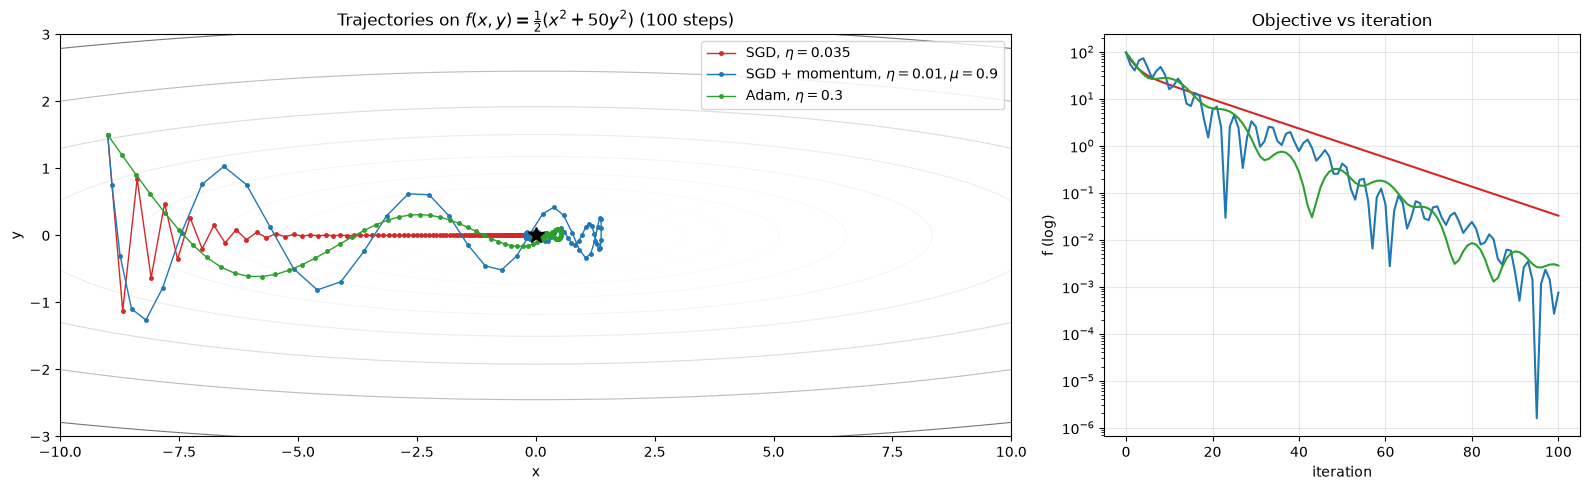

method,x after 100 steps,y after 100 steps,f after 100 steps
"SGD, lr=0.035",-0.2553,0.0000,3.26e-02
"SGD + momentum, lr=0.01, momentum=0.9",0.0237,0.0043,7.51e-04
"Adam, lr=0.3",-0.0580,-0.0067,2.82e-03


In [10]:
def f_quad(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)


def trajectory(make_opt, start=(-9.0, 1.5), steps=100):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = make_opt([p])
    path = [p.detach().clone().numpy()]
    for _ in range(steps):
        opt.zero_grad()
        f_quad(p).backward()
        opt.step()
        path.append(p.detach().clone().numpy())
    return np.array(path)


runs_2b = {
    r"SGD, $\eta=0.035$": (lambda p: MySGD(p, lr=0.035), "tab:red"),
    r"SGD + momentum, $\eta=0.01, \mu=0.9$": (lambda p: MySGD(p, lr=0.01, momentum=0.9), "tab:blue"),
    r"Adam, $\eta=0.3$": (lambda p: MyAdam(p, lr=0.3), "tab:green"),
}
paths = {k: trajectory(v[0]) for k, v in runs_2b.items()}

xs, ys = np.meshgrid(np.linspace(-10, 10, 400), np.linspace(-3, 3, 300))
fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw=dict(width_ratios=[2, 1]))
ax[0].contour(xs, ys, 0.5 * (xs ** 2 + 50 * ys ** 2), levels=np.logspace(-1, 2.6, 18), cmap="Greys",
              linewidths=0.8)
for k, path in paths.items():
    ax[0].plot(path[:, 0], path[:, 1], "o-", ms=2.5, lw=1, color=runs_2b[k][1], label=k)
    ax[1].semilogy([f_quad(q) for q in path], color=runs_2b[k][1], label=k)
ax[0].plot(0, 0, "k*", ms=12)
ax[0].set(xlabel="x", ylabel="y", title=r"Trajectories on $f(x,y)=\frac{1}{2}(x^2+50y^2)$ (100 steps)",
          xlim=(-10, 10), ylim=(-3, 3))
ax[0].legend(loc="upper right")
ax[1].set(xlabel="iteration", ylabel="f (log)", title="Objective vs iteration"); ax[1].grid(alpha=0.3)
plt.tight_layout(); savefig("task2b_trajectories"); plt.show()
display(pd.DataFrame([(k.replace("$", "").replace("\\eta", "lr").replace("\\mu", "momentum"), *path[-1],
                       f_quad(path[-1])) for k, path in paths.items()],
                     columns=["method", "x after 100 steps", "y after 100 steps", "f after 100 steps"])
        .style.format({"x after 100 steps": "{:.4f}", "y after 100 steps": "{:.4f}", "f after 100 steps": "{:.2e}"})
        .hide(axis="index"))

**Interpretation:** The final objective values are **3.3e-2 for SGD**, **7.5e-4 for momentum** and **2.8e-3 for Adam**.

* **SGD:** each step multiplies $y$ by $1-50\eta=-0.75$, so the path zig-zags across the valley, while $x$ only shrinks by a factor 0.965 per step. The step size is limited by the steep direction, so progress along the flat direction is slow; after 100 steps $x$ is still -0.26.
* **Momentum:** the velocity builds up along $x$, where the gradient keeps the same sign, giving an effective step of $\eta/(1-\mu)=0.1$. The alternating $y$ components partly cancel. The path overshoots and oscillates, but it reaches the lowest objective.
* **Adam:** each coordinate is scaled by its own gradient magnitude, so the first steps have a similar size in $x$ and $y$ and the path starts diagonally. This removes most of the effect of the different curvatures. Near the minimum the step does not shrink with the gradient, so Adam keeps oscillating slightly unless the learning rate is decayed.

The three methods use different learning rates, so this is not a general ranking.

### 2(c): Learning-rate sensitivity

The same CNN (about 0.14M parameters, no batch norm) is trained with each optimizer at learning rates 0.001, 0.01 and 0.1. All nine runs use the same seed and data order, batch size 128, a constant learning rate, 10 epochs, no augmentation and fp32. The best learning rate of each optimizer is selected by final validation accuracy.

In [11]:
class SmallCNN(nn.Module):
    def __init__(self, bn=False, p_drop=0.0, widths=(32, 64, 128)):
        super().__init__()
        c1, c2, c3 = widths

        def conv(cin, cout):
            layers = [nn.Conv2d(cin, cout, 3, padding=1, bias=not bn)]
            if bn:
                layers.append(nn.BatchNorm2d(cout))
            return layers + [nn.ReLU(inplace=True)]

        self.features = nn.Sequential(
            *conv(3, c1), *conv(c1, c1), nn.MaxPool2d(2), nn.Dropout(p_drop),
            *conv(c1, c2), *conv(c2, c2), nn.MaxPool2d(2), nn.Dropout(p_drop),
            *conv(c2, c3), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(p_drop), nn.Linear(c3, 10))

    def forward(self, x):
        return self.head(self.features(x))


print("SmallCNN parameters:", n_params(SmallCNN()))

OPTS_2C = {
    "SGD": lambda p, lr: MySGD(p, lr=lr),
    "SGD+momentum": lambda p, lr: MySGD(p, lr=lr, momentum=0.9),
    "Adam": lambda p, lr: MyAdam(p, lr=lr),
}
LRS_2C = [1e-3, 1e-2, 1e-1]


def run_2c(opt_name, lr):
    set_seed()
    model = SmallCNN().to(device)
    opt = OPTS_2C[opt_name](model.parameters(), lr)
    return fit(model, opt, 10, X_tr, y_tr, bs=128, amp=False, tag=f"{opt_name} lr={lr:g}")


R2c = {(o, lr): cached(f"task2c_{o}_lr{lr:g}", lambda o=o, lr=lr: run_2c(o, lr))
       for o in OPTS_2C for lr in LRS_2C}

SmallCNN parameters: 140714
Loaded saved run: task2c_SGD_lr0.001
[SGD lr=0.001] ep   1/10 loss 2.3037 val_acc 0.1022 (8.7s)
[SGD lr=0.001] ep   2/10 loss 2.3035 val_acc 0.1030 (5.0s)
[SGD lr=0.001] ep   3/10 loss 2.3033 val_acc 0.1032 (5.0s)
[SGD lr=0.001] ep   4/10 loss 2.3031 val_acc 0.1028 (5.0s)
[SGD lr=0.001] ep   5/10 loss 2.3029 val_acc 0.1030 (5.0s)
[SGD lr=0.001] ep   6/10 loss 2.3027 val_acc 0.1044 (5.0s)
[SGD lr=0.001] ep   7/10 loss 2.3025 val_acc 0.1032 (5.0s)
[SGD lr=0.001] ep   8/10 loss 2.3023 val_acc 0.1054 (5.0s)
[SGD lr=0.001] ep   9/10 loss 2.3021 val_acc 0.1056 (5.0s)
[SGD lr=0.001] ep  10/10 loss 2.3019 val_acc 0.1058 (5.0s)
Loaded saved run: task2c_SGD_lr0.01
[SGD lr=0.01] ep   1/10 loss 2.3029 val_acc 0.1058 (5.0s)
[SGD lr=0.01] ep   2/10 loss 2.3008 val_acc 0.1370 (5.0s)
[SGD lr=0.01] ep   3/10 loss 2.2963 val_acc 0.1206 (5.0s)
[SGD lr=0.01] ep   4/10 loss 2.2750 val_acc 0.1268 (5.0s)
[SGD lr=0.01] ep   5/10 loss 2.2139 val_acc 0.1756 (5.0s)
[SGD lr=0.01] ep   

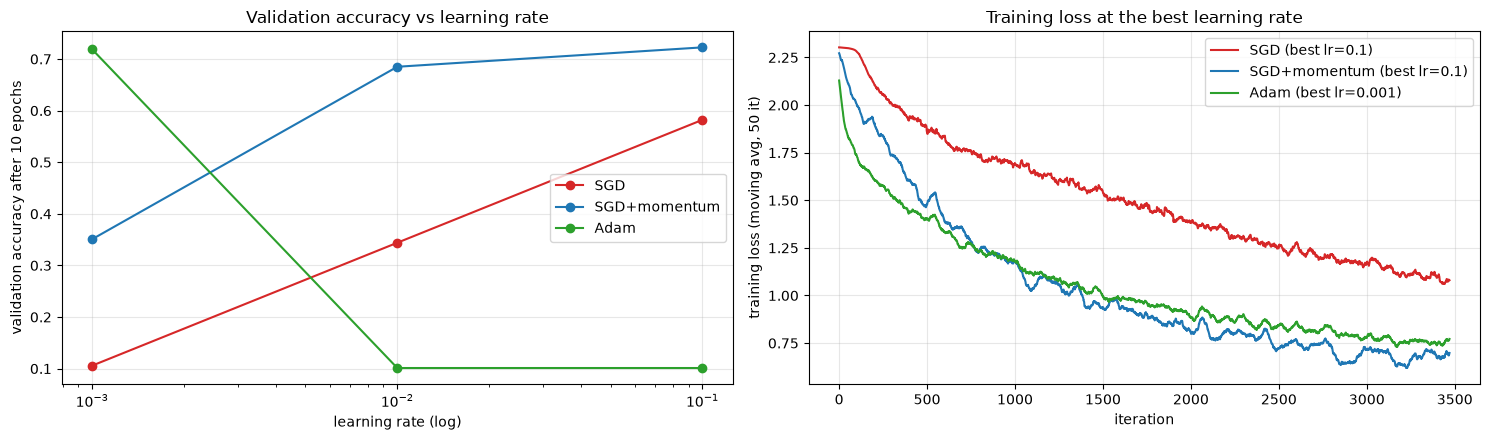

Final validation accuracy after 10 epochs:


,lr = 0.001,lr = 0.01,lr = 0.1,best lr,final train loss at best lr
SGD,10.58%,34.40%,58.22%,0.1,1.100
SGD+momentum,35.08%,68.50%,72.26%,0.1,0.672
Adam,71.88%,10.12%,10.12%,0.001,0.755


In [12]:
def final_acc(H):
    return H["val_acc"][-1] if math.isfinite(H["train_loss"][-1]) else 0.1


fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
colors = dict(zip(OPTS_2C, ["tab:red", "tab:blue", "tab:green"]))
for o in OPTS_2C:
    accs = [final_acc(R2c[(o, lr)]) for lr in LRS_2C]
    ax[0].semilogx(LRS_2C, accs, "o-", color=colors[o], label=o)
    best = LRS_2C[int(np.argmax(accs))]
    ax[1].plot(smooth(R2c[(o, best)]["iter_loss"], 50), color=colors[o], label=f"{o} (best lr={best:g})")
ax[0].set(xlabel="learning rate (log)", ylabel="validation accuracy after 10 epochs",
          title="Validation accuracy vs learning rate"); ax[0].grid(alpha=0.3); ax[0].legend()
ax[1].set(xlabel="iteration", ylabel="training loss (moving avg, 50 it)",
          title="Training loss at the best learning rate")
ax[1].grid(alpha=0.3); ax[1].legend()
plt.tight_layout(); savefig("task2c_lr_sensitivity"); plt.show()

t2c = pd.DataFrame({f"lr = {lr:g}": [final_acc(R2c[(o, lr)]) for o in OPTS_2C] for lr in LRS_2C}, index=list(OPTS_2C))
t2c["best lr"] = [f"{LRS_2C[int(np.argmax(row))]:g}" for row in t2c.values]
t2c["final train loss at best lr"] = [R2c[(o, float(b))]["train_loss"][-1] for o, b in zip(OPTS_2C, t2c["best lr"])]
print("Final validation accuracy after 10 epochs:")
display(t2c.style.format({c: "{:.2%}" for c in t2c.columns if c.startswith("lr")} |
                         {"final train loss at best lr": "{:.3f}"}).highlight_max(
    axis=None, subset=[c for c in t2c.columns if c.startswith("lr")], color="#c6efce"))

**Interpretation:**

* **SGD** needs a large learning rate. At 0.001 the loss stays at 2.30 for all 10 epochs and the accuracy is at chance level. Accuracy increases with the learning rate, with the best result **58.2%** at 0.1.
* **Momentum** behaves like SGD with a 10 times larger learning rate: momentum at 0.001 gives about the same accuracy as SGD at 0.01 (35.1% and 34.4%). It works well over a wider range (68.5% at 0.01, **72.3%** at 0.1) and reaches the lowest training loss.
* **Adam** decreases the loss fastest at the start but only works at 0.001 (**71.9%**). At 0.01 the loss stays at 2.30, and at 0.1 it explodes. Adam's step is roughly $\eta$ for every parameter regardless of the gradient size, so 0.01 is already too large for this network without batch norm.

The best learning rates differ by a factor of 100 between the optimizers, so each optimizer has to be tuned separately. In this experiment momentum gave the best accuracy and was the least sensitive to the learning rate.

## Task 3: Regularization and residual connections

### 3(a): Regularization on 5,000 training images

The small CNN from 2(c) with batch norm after every convolution is trained on the first 5,000 images of the training split and evaluated on the full validation split. All runs use the same seed, SGD with momentum 0.9, learning rate 0.05 with cosine decay, batch size 128 and 100 epochs. Training accuracy is measured on the clean (non-augmented) training images in eval mode.

* **weight decay:** $5\times10^{-4}$
* **dropout:** $p = 0.3$ after each pooling stage and before the classifier
* **flip + crop:** random horizontal flip and random 32×32 crop of the image padded by 4 pixels
* **cutout:** one random 16×16 square set to zero (the mean) in each image
* **mixup:** $\tilde x = \lambda x_i + (1-\lambda)x_j$ with loss $\lambda\,\mathrm{CE}(y_i) + (1-\lambda)\,\mathrm{CE}(y_j)$, $\lambda\sim\mathrm{Beta}(0.4, 0.4)$
* **all combined:** all of the above together

In [13]:
X_small, y_small = X_tr[:5000], y_tr[:5000]
print("5k subset class counts:", torch.bincount(y_small.cpu()).tolist())

VARIANTS_3A = {
    "baseline": dict(),
    "weight decay": dict(wd=5e-4),
    "dropout": dict(p_drop=0.3),
    "flip+crop": dict(aug=flip_crop),
    "cutout": dict(aug=cutout),
    "mixup": dict(mixup_alpha=0.4),
    "all combined": dict(wd=5e-4, p_drop=0.3, aug=compose(flip_crop, cutout), mixup_alpha=0.4),
}


def run_3a(name, n_epochs=100):
    cfg = VARIANTS_3A[name]
    set_seed()
    model = SmallCNN(bn=True, p_drop=cfg.get("p_drop", 0.0)).to(device)
    opt = MySGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=cfg.get("wd", 0.0))
    steps = n_epochs * math.ceil(len(y_small) / 128)
    return fit(model, opt, n_epochs, X_small, y_small, bs=128, aug=cfg.get("aug"),
               mixup_alpha=cfg.get("mixup_alpha", 0.0), sched=cosine_warmup(opt, steps), eval_train=True,
               tag=name)


R3a = {k: cached(f"task3a_{k.replace(' ', '_').replace('+', '_')}", lambda k=k: run_3a(k, 100))
       for k in VARIANTS_3A}

5k subset class counts: [511, 510, 506, 509, 502, 472, 500, 470, 500, 520]
Loaded saved run: task3a_baseline
[baseline] ep   1/100 loss 1.8772 val_acc 0.2764 train_acc 0.2906 (15.6s)
[baseline] ep  10/100 loss 0.9129 val_acc 0.4872 train_acc 0.5562 (3.1s)
[baseline] ep  20/100 loss 0.3398 val_acc 0.6164 train_acc 0.8358 (3.1s)
[baseline] ep  30/100 loss 0.1767 val_acc 0.6224 train_acc 0.9300 (3.1s)
[baseline] ep  40/100 loss 0.1188 val_acc 0.6326 train_acc 0.9600 (3.1s)
[baseline] ep  50/100 loss 0.0296 val_acc 0.6306 train_acc 0.9606 (3.1s)
[baseline] ep  60/100 loss 0.0096 val_acc 0.6826 train_acc 1.0000 (3.1s)
[baseline] ep  70/100 loss 0.0084 val_acc 0.6806 train_acc 1.0000 (3.1s)
[baseline] ep  80/100 loss 0.0098 val_acc 0.6770 train_acc 1.0000 (3.1s)
[baseline] ep  90/100 loss 0.0089 val_acc 0.6832 train_acc 1.0000 (3.1s)
[baseline] ep 100/100 loss 0.0088 val_acc 0.6818 train_acc 1.0000 (3.1s)
Loaded saved run: task3a_weight_decay
[weight decay] ep   1/100 loss 1.8744 val_acc 0.1

Final epoch (100) on the 5k-image training subset:


,train acc,val acc,gap (train - val),best val acc,final val loss
baseline,100.00%,68.18%,31.82%,69.04%,1.406
weight decay,100.00%,67.90%,32.10%,68.44%,1.259
dropout,98.20%,70.10%,28.10%,70.36%,0.967
flip+crop,96.80%,73.94%,22.86%,74.44%,0.953
cutout,100.00%,71.08%,28.92%,71.08%,1.199
mixup,100.00%,68.60%,31.40%,69.26%,0.965
all combined,76.18%,67.00%,9.18%,67.70%,0.929


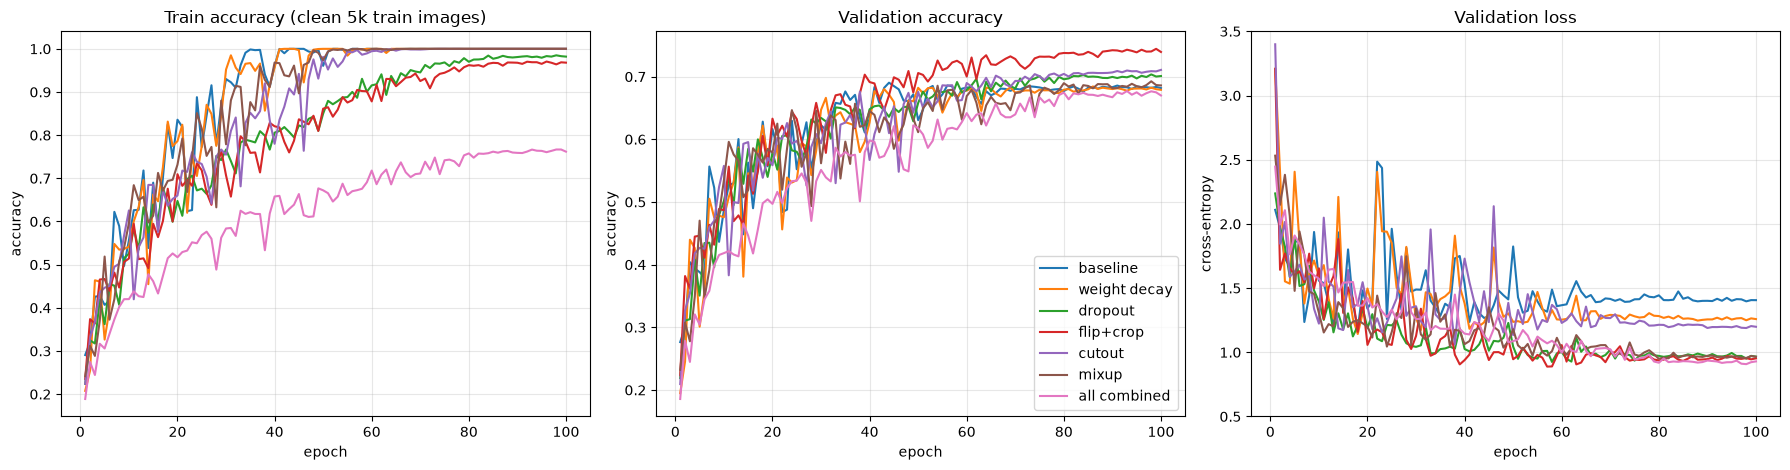

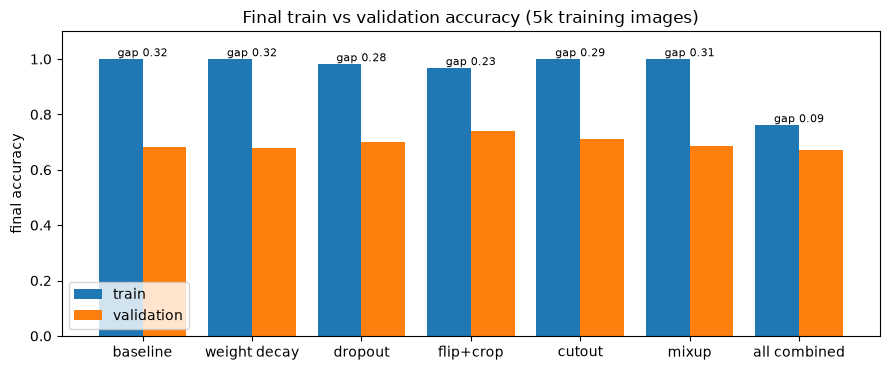

In [14]:
t3a = pd.DataFrame({k: {"train acc": H["train_acc"][-1], "val acc": H["val_acc"][-1],
                        "gap (train - val)": H["train_acc"][-1] - H["val_acc"][-1],
                        "best val acc": max(H["val_acc"]), "final val loss": H["val_loss"][-1]}
                    for k, H in R3a.items()}).T
print("Final epoch (100) on the 5k-image training subset:")
display(t3a.style.format({c: "{:.2%}" for c in t3a.columns if c != "final val loss"} | {"final val loss": "{:.3f}"})
        .highlight_max(subset=["val acc"], color="#c6efce").highlight_min(subset=["gap (train - val)"], color="#c6efce"))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
cmap = plt.get_cmap("tab10")
for i, (k, H) in enumerate(R3a.items()):
    ep = np.arange(1, len(H["val_acc"]) + 1)
    axes[0].plot(ep, H["train_acc"], color=cmap(i), label=k)
    axes[1].plot(ep, H["val_acc"], color=cmap(i), label=k)
    axes[2].plot(ep, H["val_loss"], color=cmap(i), label=k)
axes[0].set(xlabel="epoch", ylabel="accuracy", title="Train accuracy (clean 5k train images)")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Validation accuracy")
axes[2].set(xlabel="epoch", ylabel="cross-entropy", title="Validation loss", ylim=(0.5, 3.5))
for a in axes:
    a.grid(alpha=0.3)
axes[1].legend(loc="lower right")
plt.tight_layout(); savefig("task3a_regularization"); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.8))
names = list(R3a)
tr = [R3a[k]["train_acc"][-1] for k in names]; va = [R3a[k]["val_acc"][-1] for k in names]
xpos = np.arange(len(names))
ax.bar(xpos - 0.2, tr, 0.4, label="train"); ax.bar(xpos + 0.2, va, 0.4, label="validation")
for x_, t_, v_ in zip(xpos, tr, va):
    ax.text(x_, max(t_, v_) + 0.01, f"gap {t_ - v_:.2f}", ha="center", fontsize=8)
ax.set_xticks(xpos); ax.set_xticklabels(names); ax.set_ylim(0, 1.1); ax.set_ylabel("final accuracy")
ax.set_title("Final train vs validation accuracy (5k training images)"); ax.legend(loc="lower left")
plt.tight_layout(); savefig("task3a_gap"); plt.show()

**Interpretation:** The baseline fits the 5,000 training images perfectly (100% training accuracy) and reaches **68.2%** validation accuracy, a gap of **31.8 points**.

* **Flip + crop** is the best single method (**73.9%**, gap 22.9). Flipped and slightly shifted images keep the same class, so this works like adding new training images.
* **Cutout** (71.1%) and **dropout** (70.1%) also help. Cutout makes the model use more parts of the object, and dropout reduces the reliance on individual features. Only dropout and flip + crop keep the training accuracy below 100%.
* **Weight decay** does not change the accuracy (67.9%). With batch norm after every convolution the output does not depend on the scale of the convolution weights, so weight decay mainly changes the effective learning rate. It does lower the validation loss from 1.41 to 1.26.
* **Mixup** gives a similar accuracy to the baseline (68.6%), but the validation loss drops from 1.41 to 0.97, so the predictions are less overconfident.
* **All combined** has the smallest gap (**9.2 points**) and the lowest validation loss, but the training accuracy is only 76.2% and the validation accuracy (67.0%) is below flip + crop alone. Together the methods regularize too strongly for this small model and a 100-epoch budget; the curves are still rising at the end of training.

Combining all regularizers reduces the gap but does not give the best accuracy here.

### 3(b): Plain and residual networks of depth 6n + 2

Following He et al. (2016): a 3×3 convolution with 16 channels, three stages of $n$ blocks with 16/32/64 channels (each block has two 3×3 convolutions with batch norm), global average pooling and a linear layer. The first convolution of stages 2 and 3 has stride 2. Depths 8, 20 and 56 correspond to $n$ = 1, 3 and 9. Convolutions use Kaiming-normal initialization.

The only difference between the two families is the shortcut: a residual block computes $\mathrm{ReLU}(F(x) + x)$ and a plain block $\mathrm{ReLU}(F(x))$. When the shape changes, the shortcut subsamples with stride 2 and zero-pads the extra channels (option A), so it has no parameters and both networks of the same depth have exactly the same parameters.

All six networks are trained with SGD (momentum 0.9, weight decay $10^{-4}$), batch size 128, learning rate 0.1 with one epoch of warm-up and cosine decay, flip + crop augmentation, for 20 epochs on the 45,000 training images.

In [15]:
class ShortcutA(nn.Module):
    """Identity shortcut; on a shape change, subsample spatially and zero-pad the new channels."""
    def __init__(self, c_in, c_out, stride):
        super().__init__()
        self.stride, self.pad = stride, c_out - c_in

    def forward(self, x):
        if self.stride > 1:
            x = x[:, :, ::self.stride, ::self.stride]
        if self.pad > 0:
            x = F.pad(x, (0, 0, 0, 0, self.pad // 2, self.pad - self.pad // 2))
        return x


class ShortcutB(nn.Sequential):
    """Projection shortcut (1x1 conv + BN) on a shape change, identity otherwise."""
    def __init__(self, c_in, c_out, stride):
        if stride == 1 and c_in == c_out:
            super().__init__()
        else:
            super().__init__(nn.Conv2d(c_in, c_out, 1, stride, bias=False), nn.BatchNorm2d(c_out))


class BasicBlock(nn.Module):
    def __init__(self, c_in, c_out, stride, residual=True, shortcut="A"):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.residual = residual
        if residual:
            self.shortcut = (ShortcutA if shortcut == "A" else ShortcutB)(c_in, c_out, stride)

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class CifarNet(nn.Module):
    """CIFAR ResNet / plain net: stem + 3 stages + GAP + FC. blocks=(n, n, n) gives depth 6n+2."""
    def __init__(self, blocks=(3, 3, 3), widths=(16, 32, 64), residual=True, shortcut="A", zero_init_last_bn=False):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]),
                                  nn.ReLU(inplace=True))
        layers, c_in = [], widths[0]
        for s, (n, w) in enumerate(zip(blocks, widths)):
            for b in range(n):
                layers.append(BasicBlock(c_in, w, 2 if (s > 0 and b == 0) else 1, residual, shortcut))
                c_in = w
        self.stages = nn.Sequential(*layers)
        self.fc = nn.Linear(c_in, 10)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight); nn.init.zeros_(m.bias)
        if zero_init_last_bn and residual:
            for m in self.modules():
                if isinstance(m, BasicBlock):
                    nn.init.zeros_(m.bn2.weight)

    def forward(self, x):
        x = self.stages(self.stem(x))
        return self.fc(torch.flatten(F.adaptive_avg_pool2d(x, 1), 1))


def depth_net(depth, residual):
    n = (depth - 2) // 6
    return CifarNet(blocks=(n, n, n), residual=residual)


for d in (8, 20, 56):
    print(f"depth {d:2d}: params plain {n_params(depth_net(d, False)):,}  residual {n_params(depth_net(d, True)):,}")

depth  8: params plain 75,290  residual 75,290
depth 20: params plain 269,722  residual 269,722
depth 56: params plain 853,018  residual 853,018


In [16]:
def run_3b(depth, residual, n_epochs=20):
    set_seed()
    model = depth_net(depth, residual).to(device)
    opt = MySGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
    spe = math.ceil(len(y_tr) / 128)
    return fit(model, opt, n_epochs, X_tr, y_tr, bs=128, aug=flip_crop,
               sched=cosine_warmup(opt, n_epochs * spe, warmup_steps=spe),
               tag=f"{'res' if residual else 'plain'}-{depth}")


R3b = {(d, r): cached(f"task3b_{'res' if r else 'plain'}{d}", lambda d=d, r=r: run_3b(d, r, 20))
       for d in (8, 20, 56) for r in (False, True)}

Loaded saved run: task3b_plain8
[plain-8] ep   1/20 loss 1.7175 val_acc 0.3700 (6.6s)
[plain-8] ep   2/20 loss 1.2060 val_acc 0.4112 (4.9s)
[plain-8] ep   4/20 loss 0.9305 val_acc 0.6416 (4.9s)
[plain-8] ep   6/20 loss 0.7973 val_acc 0.7008 (4.9s)
[plain-8] ep   8/20 loss 0.6970 val_acc 0.7340 (5.0s)
[plain-8] ep  10/20 loss 0.6266 val_acc 0.7678 (4.9s)
[plain-8] ep  12/20 loss 0.5706 val_acc 0.7922 (4.9s)
[plain-8] ep  14/20 loss 0.5251 val_acc 0.8038 (4.9s)
[plain-8] ep  16/20 loss 0.4880 val_acc 0.8170 (4.9s)
[plain-8] ep  18/20 loss 0.4634 val_acc 0.8284 (4.9s)
[plain-8] ep  20/20 loss 0.4495 val_acc 0.8294 (4.9s)
Loaded saved run: task3b_res8
[res-8] ep   1/20 loss 1.7412 val_acc 0.4592 (5.3s)
[res-8] ep   2/20 loss 1.2452 val_acc 0.5592 (5.3s)
[res-8] ep   4/20 loss 0.9396 val_acc 0.5686 (5.3s)
[res-8] ep   6/20 loss 0.8013 val_acc 0.6724 (5.3s)
[res-8] ep   8/20 loss 0.7190 val_acc 0.7274 (5.3s)
[res-8] ep  10/20 loss 0.6539 val_acc 0.7548 (5.2s)
[res-8] ep  12/20 loss 0.5968 va

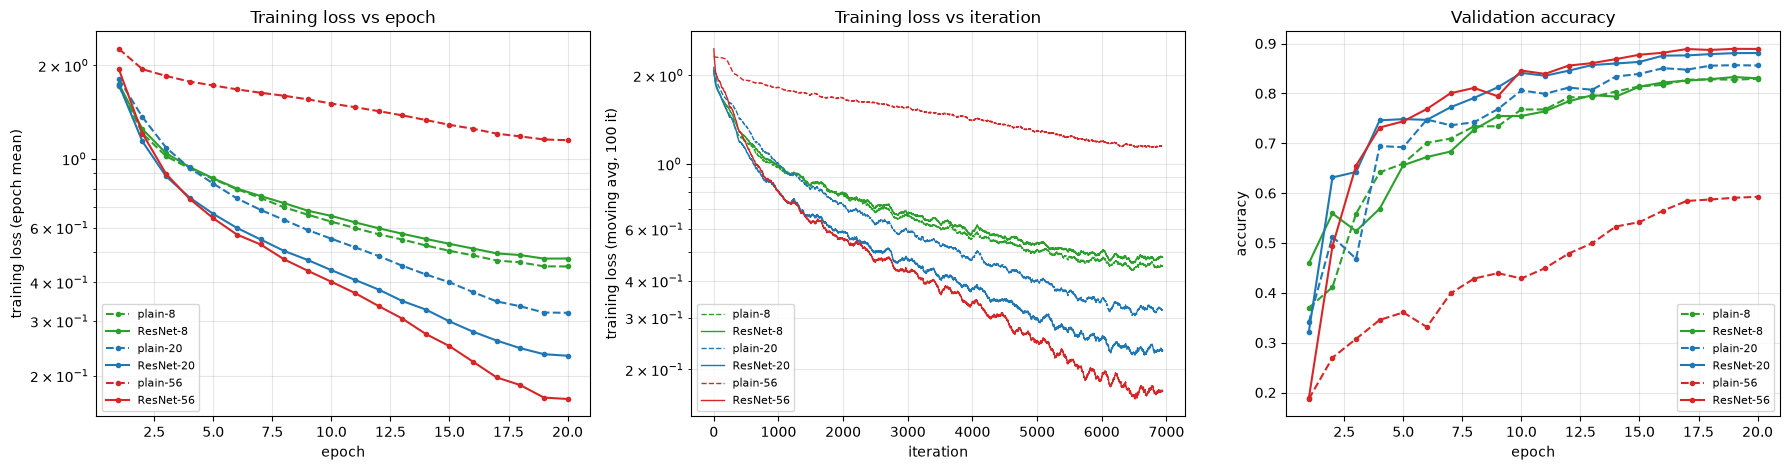

Final epoch (20):


,parameters,plain: train loss,residual: train loss,plain: val acc,residual: val acc,plain: s/epoch,residual: s/epoch
depth,,,,,,,
8,"75,290",0.4495,0.4767,82.94%,83.04%,5.0,5.3
20,"269,722",0.3187,0.2317,85.60%,88.10%,13.4,14.1
56,"853,018",1.1468,0.1682,59.26%,88.92%,39.3,41.1


In [17]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
dcol = {8: "tab:green", 20: "tab:blue", 56: "tab:red"}
for (d, r), H in R3b.items():
    ep = np.arange(1, len(H["train_loss"]) + 1)
    style = dict(color=dcol[d], ls="-" if r else "--", label=f"{'ResNet' if r else 'plain'}-{d}")
    ax[0].plot(ep, H["train_loss"], marker="o", ms=3, **style)
    ax[1].plot(smooth(H["iter_loss"], 100), lw=1, **style)
    ax[2].plot(ep, H["val_acc"], marker="o", ms=3, **style)
ax[0].set(xlabel="epoch", ylabel="training loss (epoch mean)", title="Training loss vs epoch", yscale="log")
ax[1].set(xlabel="iteration", ylabel="training loss (moving avg, 100 it)", title="Training loss vs iteration",
          yscale="log")
ax[2].set(xlabel="epoch", ylabel="accuracy", title="Validation accuracy")
for a in ax:
    a.grid(alpha=0.3, which="both"); a.legend(fontsize=8)
plt.tight_layout(); savefig("task3b_plain_vs_residual"); plt.show()

t3b = pd.DataFrame([{"depth": d, "parameters": n_params(depth_net(d, True)),
                     "plain: train loss": R3b[(d, False)]["train_loss"][-1],
                     "residual: train loss": R3b[(d, True)]["train_loss"][-1],
                     "plain: val acc": R3b[(d, False)]["val_acc"][-1],
                     "residual: val acc": R3b[(d, True)]["val_acc"][-1],
                     "plain: s/epoch": np.mean(R3b[(d, False)]["time"]),
                     "residual: s/epoch": np.mean(R3b[(d, True)]["time"])} for d in (8, 20, 56)]).set_index("depth")
print("Final epoch (20):")
display(t3b.style.format({"parameters": "{:,}"} | {c: "{:.4f}" for c in t3b.columns if "loss" in c}
                         | {c: "{:.2%}" for c in t3b.columns if "acc" in c}
                         | {c: "{:.1f}" for c in t3b.columns if "s/epoch" in c}))

**Interpretation:**

* **Plain networks get worse with depth.** Plain-56 ends with a training loss of **1.15**, much higher than plain-20 (0.32) and plain-8 (0.45), and its validation accuracy is only 59.3%. Since the *training* loss is higher, this is an optimization problem and not overfitting. A 56-layer network can represent anything the 8-layer network can, but SGD does not find such a solution. This is the degradation problem described by He et al.
* **Residual networks improve with depth.** The training loss goes from 0.48 to 0.23 to **0.17** and the validation accuracy from 83.0% to 88.1% to **88.9%**. Each block only has to learn a correction $F(x)$ that is added to $x$, so the identity is easy to represent, and the shortcuts pass the gradient directly to the early layers.
* At depth 8 the shortcut makes no difference. The gap grows with depth: 2.5 points at depth 20 and 29.7 points at depth 56.
* The deeper networks cost more compute: ResNet-56 takes about 8 times longer per epoch than ResNet-8.

## Task 4 (optional): Best CNN with at most 500k parameters and 20 epochs

**Design.** Task 3(b) showed that residual networks train well, and with only 20 epochs a shallow, wider network is a better use of the budget than a deep, thin one. The model is a ResNet with 2 blocks per stage (14 layers), widths 26/52/104, 1×1 convolution shortcuts where the shape changes, and the last batch-norm scale of each block initialized to zero, so that each block starts as the identity. It has 460,548 parameters.

Training: SGD with Nesterov momentum 0.9, batch size 128, peak learning rate 0.1 with one epoch of warm-up and cosine decay, weight decay $5\times10^{-4}$, label smoothing 0.1, flip + crop and cutout (16×16), 20 epochs on the 45,000 training images.

**Ablation.** Each variant changes one design choice and is trained with the same seed and budget. The final model is the variant with the best final validation accuracy, and only this model is evaluated on the test set.

In [18]:
T4_ARCH = dict(blocks=(2, 2, 2), widths=(26, 52, 104), shortcut="B", zero_init_last_bn=True)
T4_PARAMS = n_params(CifarNet(**T4_ARCH))
print(f"Task 4 model parameters: {T4_PARAMS:,}")
assert T4_PARAMS <= 500_000

VARIANTS_4 = {
    "full model": dict(),
    "no shortcut (plain)": dict(residual=False),
    "no augmentation": dict(aug=None),
    "no cutout (flip+crop only)": dict(aug=flip_crop),
    "no weight decay": dict(wd=0.0),
    "no label smoothing": dict(ls=0.0),
    "AdamW instead of SGD": dict(opt="adamw"),
}


def run_4(name, n_epochs=20):
    cfg = VARIANTS_4[name]
    set_seed()
    model = CifarNet(**{**T4_ARCH, "residual": cfg.get("residual", True)}).to(device)
    wd = cfg.get("wd", 5e-4)
    if cfg.get("opt") == "adamw":
        opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=5e-2)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=wd)
    spe = math.ceil(len(y_tr) / 128)
    H = fit(model, opt, n_epochs, X_tr, y_tr, bs=128, aug=cfg.get("aug", compose(flip_crop, cutout)),
            label_smoothing=cfg.get("ls", 0.1), sched=cosine_warmup(opt, n_epochs * spe, warmup_steps=spe),
            tag=name)
    H["params"] = n_params(model)
    torch.save(model.state_dict(), f"{CKPT}/task4_{name.replace(' ', '_')}.pt")
    return H


R4 = {k: cached(f"task4_{k.replace(' ', '_').replace('(', '').replace(')', '').replace('+', '_')}",
                lambda k=k: run_4(k, 20)) for k in VARIANTS_4}

Task 4 model parameters: 460,548
Loaded saved run: task4_full_model
[full model] ep   1/20 loss 1.9915 val_acc 0.4166 (17.3s)
[full model] ep   2/20 loss 1.6357 val_acc 0.4784 (15.0s)
[full model] ep   4/20 loss 1.3462 val_acc 0.6280 (15.0s)
[full model] ep   6/20 loss 1.2196 val_acc 0.6546 (15.0s)
[full model] ep   8/20 loss 1.1243 val_acc 0.7032 (15.0s)
[full model] ep  10/20 loss 1.0550 val_acc 0.7668 (15.0s)
[full model] ep  12/20 loss 0.9978 val_acc 0.7980 (15.0s)
[full model] ep  14/20 loss 0.9393 val_acc 0.8452 (15.0s)
[full model] ep  16/20 loss 0.8796 val_acc 0.8670 (15.0s)
[full model] ep  18/20 loss 0.8405 val_acc 0.8882 (15.0s)
[full model] ep  20/20 loss 0.8228 val_acc 0.8896 (15.0s)
Loaded saved run: task4_no_shortcut_plain
[no shortcut (plain)] ep   1/20 loss 1.8539 val_acc 0.4826 (13.8s)
[no shortcut (plain)] ep   2/20 loss 1.4760 val_acc 0.6194 (13.8s)
[no shortcut (plain)] ep   4/20 loss 1.2455 val_acc 0.7080 (13.8s)
[no shortcut (plain)] ep   6/20 loss 1.1478 val_acc

Ablation, final epoch (20), validation split:


,parameters,val acc,change vs full model,best val acc,final train loss
full model,"460,548",88.96%,+0.00%,89.12%,0.8228
no shortcut (plain),"453,476",88.78%,-0.18%,88.78%,0.8146
no augmentation,"460,548",86.54%,-2.42%,86.54%,0.5262
no cutout (flip+crop only),"460,548",90.78%,+1.82%,90.86%,0.6617
no weight decay,"460,548",86.48%,-2.48%,86.48%,0.9057
no label smoothing,"460,548",89.26%,+0.30%,89.26%,0.3682
AdamW instead of SGD,"460,548",87.10%,-1.86%,87.10%,0.8752


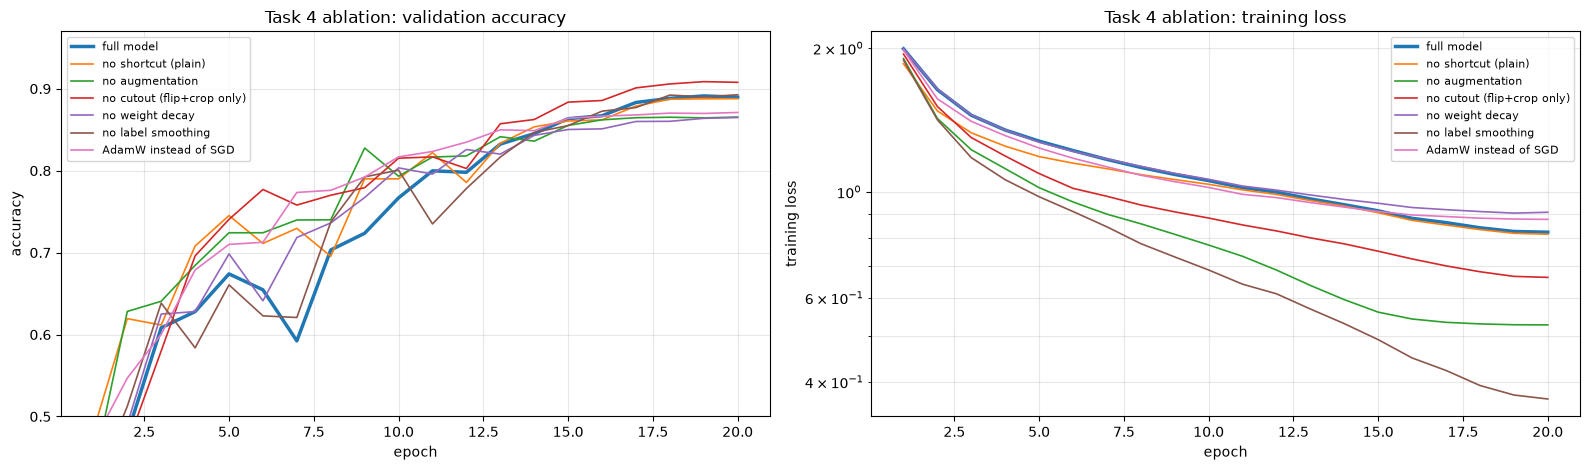

In [19]:
base = R4["full model"]["val_acc"][-1]
t4 = pd.DataFrame({k: {"parameters": H["params"], "val acc": H["val_acc"][-1],
                       "change vs full model": H["val_acc"][-1] - base, "best val acc": max(H["val_acc"]),
                       "final train loss": H["train_loss"][-1]} for k, H in R4.items()}).T
print("Ablation, final epoch (20), validation split:")
display(t4.style.format({"parameters": "{:,.0f}", "val acc": "{:.2%}", "change vs full model": "{:+.2%}",
                         "best val acc": "{:.2%}", "final train loss": "{:.4f}"})
        .highlight_max(subset=["val acc"], color="#c6efce"))

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
for i, (k, H) in enumerate(R4.items()):
    ep = np.arange(1, len(H["val_acc"]) + 1)
    lw = 2.5 if k == "full model" else 1.2
    ax[0].plot(ep, H["val_acc"], color=cmap(i), lw=lw, label=k)
    ax[1].plot(ep, H["train_loss"], color=cmap(i), lw=lw, label=k)
ax[0].set(xlabel="epoch", ylabel="accuracy", title="Task 4 ablation: validation accuracy", ylim=(0.5, 0.97))
ax[1].set(xlabel="epoch", ylabel="training loss", title="Task 4 ablation: training loss", yscale="log")
for a in ax:
    a.grid(alpha=0.3, which="both"); a.legend(fontsize=8)
plt.tight_layout(); savefig("task4_ablation"); plt.show()

**Interpretation:** The full model reaches **88.96%** validation accuracy.

* **Cutout:** removing it gives the best result, **90.78%** (+1.8 points). With cutout the training loss stays higher (0.82 vs 0.66), so the model underfits in 20 epochs. Cutout seems to need a longer training schedule.
* **Augmentation:** without any augmentation the accuracy drops to 86.54% (-2.4) and the training loss is the lowest of all label-smoothed runs (0.53), so the model memorises the training set.
* **Weight decay:** without it the accuracy drops to 86.48% (-2.5) and the training loss is *higher* (0.91). With batch norm, weight decay keeps the weight norms small, which keeps the effective learning rate high; without it training slows down.
* **Optimizer:** AdamW (learning rate 0.002, weight decay 0.05) gives 87.10% (-1.9), below SGD with Nesterov momentum.
* **Shortcut:** removing the shortcuts costs only 0.2 points at 14 layers, which agrees with Task 3(b) where the difference is small for shallow networks.
* **Label smoothing:** removing it changes the accuracy by +0.3 points, which is within run-to-run variation.

With label smoothing 0.1 the training loss cannot go below about 0.5, so training losses are only compared between runs that use it. Following the selection rule, the final model is the residual network **without cutout** (flip + crop, weight decay, label smoothing, SGD with Nesterov momentum), with 90.78% validation accuracy.

### Final test evaluation

The saved weights of the selected model are evaluated once on the 10,000 test images. The result is saved, so the test set is not evaluated again when the notebook is re-run.

selected on validation: no cutout (flip+crop only) (val acc 0.9078)
Loaded saved run: task4_test
Final model: no cutout (flip+crop only)  |  parameters 460,548  |  TEST ACCURACY = 0.9036


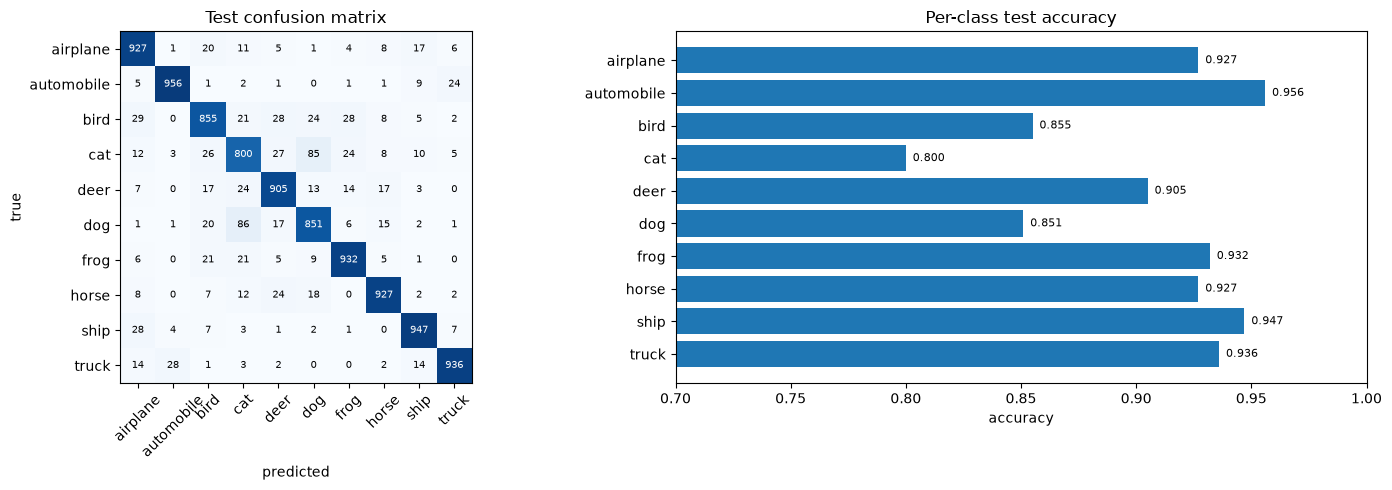

In [20]:
FINAL = max(R4, key=lambda k: R4[k]["val_acc"][-1])
print("selected on validation:", FINAL, f"(val acc {R4[FINAL]['val_acc'][-1]:.4f})")


def test_once():
    cfg = VARIANTS_4[FINAL]
    model = CifarNet(**{**T4_ARCH, "residual": cfg.get("residual", True)}).to(device)
    model.load_state_dict(torch.load(f"{CKPT}/task4_{FINAL.replace(' ', '_')}.pt", map_location=device))
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(y_te), 1000):
            with torch.autocast(device.type, dtype=torch.float16, enabled=AMP):
                preds.append(model(X_te[i:i + 1000].to(device)).argmax(1).cpu())
    preds = torch.cat(preds)
    cm = torch.zeros(10, 10, dtype=torch.long)
    for t, p in zip(y_te, preds):
        cm[t, p] += 1
    return dict(model=FINAL, test_acc=(preds == y_te).float().mean().item(), confusion=cm.tolist())


T4_TEST = cached("task4_test", test_once)
print(f"Final model: {T4_TEST['model']}  |  parameters {T4_PARAMS:,}  |  TEST ACCURACY = {T4_TEST['test_acc']:.4f}")

cm = np.array(T4_TEST["confusion"])
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
im = ax[0].imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
for i in range(10):
    for j in range(10):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if i == j else "black")
ax[0].set_xticks(range(10)); ax[0].set_xticklabels(CLASSES, rotation=45); ax[0].set_yticks(range(10))
ax[0].set_yticklabels(CLASSES); ax[0].set(xlabel="predicted", ylabel="true", title="Test confusion matrix")
per_class = cm.diagonal() / cm.sum(1)
ax[1].barh(CLASSES, per_class, color="tab:blue"); ax[1].set_xlim(0.7, 1.0)
for i, v in enumerate(per_class):
    ax[1].text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=8)
ax[1].set(title="Per-class test accuracy", xlabel="accuracy"); ax[1].invert_yaxis()
plt.tight_layout(); savefig("task4_test"); plt.show()

**Interpretation:** The final model reaches **90.36% test accuracy** with 460,548 parameters and 20 training epochs. This is 0.4 points below its validation accuracy (90.78%), so choosing between seven variants on the validation split did not overfit it much.

The vehicle classes are the easiest (automobile 95.6%, ship 94.7%, truck 93.6%). The hardest are **cat (80.0%) and dog (85.1%)**, which are mostly confused with each other: 85 cats are predicted as dog and 86 dogs as cat. Bird (85.5%) is confused with airplane, deer and frog.